# San Ramon 2025-26: the deep-learning picker in SeisComP, side by side with 2015

**What was tested.** SED's scdlrtpicker plugin runs deep-learning (DL) phase pickers inside SeisComP's automatic
picker scautopick. A short-term/long-term average (STA/LTA) detector trigger starts a neural network that places the P
pick; a P pick starts a second network that looks for the S arrival. Step 14 ran the plugin offline on the
analyst-reviewed test events of the 2025-26 San Ramon sequence (Northern California) with exactly the settings of
step 12's test on the 2015 San Ramon swarm: the same four models (`phasenet_instance`, `phasenet_original`, `phasenet_scedc` and
`eqtp_ncedc`), the same detector, thresholds, time windows and station-binding rules. The cell after the parameters
lists the test events of both years.

**What the picks are compared with.** The reference is the set of reviewed analyst picks of the Northern California
Seismic System (NCSS). *Recall* is the share of analyst picks that the DL picker also found; it is a fair measure.
*Precision* is the share of DL picks that an analyst also picked; it is only a lower bound, because the analysts did
not pick every station and picked S rarely. A *complete 3-C record* is a station record with a vertical and two
horizontal channels (three components, 3-C) that covers the whole event file in one piece; only on such records can
a 3-component model be judged fairly. This notebook re-picks nothing: it loads the result files of both runs, and every
number in the text is formatted from them.

## Parameters

In [1]:
# ============================== PARAMETERS ==============================
# every setting of this notebook; nothing below changes these values
import time as _time
T_START = _time.time()                                   # the run time is printed at the very end
PROJECT = "/home/msseo/works/74.SeisComP_rtDD_DLpicker"
RUNS = {"2015": f"{PROJECT}/runs/sanramon/dlpicker",     # step 12, the 2015 swarm (read only)
        "2025-26": f"{PROJECT}/runs/sanramon2026/dlpicker"}   # step 14, the 2025-26 sequence (read only)
EVENTS = {"2015": f"{PROJECT}/data/sanramon_2015/inputs/dl_subset_events.csv",      # the test events of each year
          "2025-26": f"{PROJECT}/data/sanramon_2026/inputs/dl_subset_events.csv"}
YEAR_LABEL = {"2015": "2015 swarm (step 12)", "2025-26": "2025-26 sequence (step 14)"}
SIDE_BY_SIDE = f"{RUNS['2025-26']}/analysis/side_by_side_2015_vs_2026.csv"   # step 14's own year table (cross-check only)
EXTRA_CHECKS = f"{RUNS['2025-26']}/analysis/extra_checks.json"               # step 14 extra checks (overlap file, hn set)
FIG_DIR = f"{PROJECT}/notebooks/figures"                 # figures as 09_*.png (200 dpi) and 09_*.pdf
FIG_DPI = 200

# --- what is compared ---
MODELS = ["phasenet_instance", "phasenet_original", "phasenet_scedc", "eqtp_ncedc"]   # main binding set, as in step 12
RECOMMENDED = "phasenet_instance"      # the model shown over the four sets of analyst picks (Figure 1c)
POLARITY_MODEL = "eqtp_ncedc"          # the only model with a first-motion polarity output
POL_THRESHOLDS = (0.5, 0.7)            # polarityMinConfidence: plugin default and the stricter value of step 12
POL_GROUP = "direct_sense"             # normally oriented verticals (dip -90 deg, gain > 0)
POL_GROUP_INVERTED = "inverted_sense"  # gain < 0 or dip +90 deg (caveat in the text only)
ISOLATED_CLASS = "none within 120 s"   # step 12's class of events with no other catalog event in the file
OVERLAP_EVENT = {"2015": "72540760", "2025-26": "75283011"}   # the overlap test event of each year (step 12/14)

# --- figure layout ---
BAR_GROUP_WIDTH = 0.80                 # width of one group of year bars (x units = one model)
FIG_HEIGHT_IN = 4.2

In [2]:
# imports, Helvetica, colors and labels (model colors and markers identical to notebook 07)
import os
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from IPython.display import display, Markdown
import sys
sys.path.insert(0, "/home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/lib")
import nbfont
nbfont.use_helvetica(verbose=True)
import importlib
import nb09_helpers as h
importlib.reload(h)

plt.rcParams.update({"font.size": 9, "axes.titlesize": 9.0, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 100, "hatch.linewidth": 0.6,
                     "axes.spines.top": True, "axes.spines.right": True, "axes.spines.left": True,
                     "axes.spines.bottom": True, "mathtext.cal": "Helvetica:italic"})
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 200)

COL = {"phasenet_instance": "#56B4E9", "phasenet_original": "#E69F00", "phasenet_scedc": "#882255",
       "eqtp_ncedc": "#332288"}
MARK = {"phasenet_instance": "D", "phasenet_original": "s", "phasenet_scedc": "h", "eqtp_ncedc": "o"}
SHORT = {"phasenet_instance": "PhaseNet INSTANCE", "phasenet_original": "PhaseNet original",
         "phasenet_scedc": "PhaseNet SCEDC", "eqtp_ncedc": "EQTP NCEDC"}
TICK = {v: SHORT[v].replace(" ", "\n", 1) for v in MODELS}
MAG_TYPE = {"W": "Mw", "D": "Md", "L": "ML"}
YEARS = list(RUNS)
PH = ["P", "S"]
DEN = [("all", "All usable\nanalyst picks"), ("with_data", "With waveform\ndata"), ("3c", "At 3-C\nstations"),
       ("3c_complete", "On complete\n3-C records")]
FIGS = {}
print("versions: python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

font family in use: Helvetica (8 faces registered)
versions: python 3.12.15 | numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2


## Loaded results

The next cell reads the result files of both runs as they are on disk (listed with their modification times), checks
the values it uses against step 14's own year table (`side_by_side_2015_vs_2026.csv`), and lists the test events.

In [3]:
# load the result files of both runs (no picking), and check them against step 14's side-by-side table
SBM, NB, OW, COST, SUMM, PRC, EVT, NEIGH, BYEV, COV = ({} for _ in range(10))
used = []
for y, R in RUNS.items():
    A = f"{R}/analysis"
    f = dict(sbm=f"{A}/summary_by_model.csv", nb=f"{A}/by_neighbour.csv", ow=f"{A}/outside_window.csv",
             cost=f"{A}/cost.csv", summ=f"{A}/summary.json", prc=f"{A}/polarity_reference_check.json",
             neigh=f"{A}/event_neighbours.csv", byev=f"{A}/by_event.csv", cov=f"{R}/config/coverage_bound.csv")
    SBM[y] = pd.read_csv(f["sbm"]).set_index(["variant", "phase"])
    NB[y] = pd.read_csv(f["nb"], dtype={"value": str}).set_index(["variant", "phase", "value"])
    OW[y] = pd.read_csv(f["ow"]).set_index(["variant", "phase"])
    COST[y] = pd.read_csv(f["cost"]).set_index("variant")
    SUMM[y] = json.load(open(f["summ"]))
    PRC[y] = json.load(open(f["prc"]))
    NEIGH[y] = pd.read_csv(f["neigh"], dtype={"event_id": str, "nearest_other_event": str}).set_index("event_id")
    BYEV[y] = pd.read_csv(f["byev"], dtype={"value": str})
    BYEV[y]["event_id"] = BYEV[y]["value"].str.split().str[0]
    COV[y] = pd.read_csv(f["cov"], dtype={"event_id": str, "location": str})
    EVT[y] = pd.read_csv(EVENTS[y], dtype={"event_id": str})
    used += [(y, p) for p in list(f.values()) + [EVENTS[y]]]
XC = json.load(open(EXTRA_CHECKS))
SBS = pd.read_csv(SIDE_BY_SIDE)
used += [("2025-26", EXTRA_CHECKS), ("2025-26", SIDE_BY_SIDE)]
POL = {y: SUMM[y]["polarity"][POLARITY_MODEL] for y in YEARS}
for y, p in used:
    print(f"{y:8s} {pd.Timestamp(os.path.getmtime(p), unit='s'):%Y-%m-%d %H:%M}  {os.path.relpath(p, PROJECT)}")

# share of complete records in the main binding set (same rule as step 14's 14_side_by_side.py)
COMPLETE = {y: (int(COV[y].loc[COV[y].role == "main", "complete"].sum()), int((COV[y].role == "main").sum())) for y in YEARS}

# cross-check: the values used here, formatted as in the side-by-side table, must equal its entries
SBS_COL = {"2015": "sanramon_2015", "2025-26": "sanramon_2025_26"}
def sbs(section, quantity, y):
    q = SBS[(SBS.section == section) & (SBS.quantity == quantity)]
    assert len(q) == 1, (section, quantity)
    return str(q[SBS_COL[y]].iloc[0])
checks = []
for y in YEARS:
    k, n = COMPLETE[y]
    checks.append(sbs("data", "main-set station-event records complete", y) == f"{k}/{n} = {k / n:.2f}")
    for v in MODELS:
        s = SBM[y].loc[(v, "P")]
        checks.append(sbs(v, "P recall: all / with data / 3-C / complete", y)
                      == " / ".join(f"{s[f'recall_{key}']:.2f}" for key, _ in DEN))
        checks.append(sbs(v, "P recall complete: no event within 120 s / nearest <= 15 s", y)
                      .startswith(f"{NB[y].loc[(v, 'P', ISOLATED_CLASS), 'recall_3c_complete']:.2f} "))
        checks.append(sbs(v, "false P picks per station-hour (noise span)", y)
                      .startswith(f"{OW[y].loc[(v, 'P'), 'false_per_station_hour_searchable']:.2f} "))
        checks.append(sbs(v, "CPU s per station-hour / ms per window", y)
                      .startswith(f"{COST[y].loc[v, 'cpu_s_per_station_hour']:.3f} "))
    for thr in POL_THRESHOLDS:
        g = POL[y][f"thr_{thr:g}"][POL_GROUP]
        checks.append(sbs(f"polarity ({POLARITY_MODEL})", f"threshold {thr:g}: agreement normal / inverted channels", y)
                      .startswith(f"{g['agreement']:.2f} (n {g['n_matched_with_analyst_fm']})"))
assert all(checks), f"{len(checks) - sum(checks)} values differ from {os.path.basename(SIDE_BY_SIDE)}"
print(f"\n{sum(checks)} of {len(checks)} values agree with {os.path.basename(SIDE_BY_SIDE)}")

# the test events of both years
lines = []
for y in YEARS:
    e = EVT[y]
    big = e.loc[e.pref_mag.idxmax()]
    lines.append(f"- **{YEAR_LABEL[y]}:** {len(e)} test events, M {e.pref_mag.min():.2f}–{e.pref_mag.max():.2f}; the largest is "
                 f"{MAG_TYPE.get(big.pref_mag_type, 'M')} {big.pref_mag:.2f} on {big.origin_time_utc[:10]} (event {big.event_id}).")
display(Markdown("\n".join(lines)))

2015     2026-10-17 13:22  runs/sanramon/dlpicker/analysis/summary_by_model.csv
2015     2026-10-17 13:22  runs/sanramon/dlpicker/analysis/by_neighbour.csv
2015     2026-10-17 13:23  runs/sanramon/dlpicker/analysis/outside_window.csv
2015     2026-10-17 13:23  runs/sanramon/dlpicker/analysis/cost.csv
2015     2026-10-17 13:23  runs/sanramon/dlpicker/analysis/summary.json
2015     2026-10-17 13:41  runs/sanramon/dlpicker/analysis/polarity_reference_check.json
2015     2026-10-17 13:20  runs/sanramon/dlpicker/analysis/event_neighbours.csv
2015     2026-10-17 13:22  runs/sanramon/dlpicker/analysis/by_event.csv
2015     2026-10-17 12:39  runs/sanramon/dlpicker/config/coverage_bound.csv
2015     2026-10-17 04:09  data/sanramon_2015/inputs/dl_subset_events.csv
2025-26  2026-10-18 05:39  runs/sanramon2026/dlpicker/analysis/summary_by_model.csv
2025-26  2026-10-18 05:39  runs/sanramon2026/dlpicker/analysis/by_neighbour.csv
2025-26  2026-10-18 05:40  runs/sanramon2026/dlpicker/analysis/outside_

- **2015 swarm (step 12):** 26 test events, M 0.81–3.60; the largest is Mw 3.60 on 2015-10-19 (event 72540765).
- **2025-26 sequence (step 14):** 26 test events, M 0.60–4.18; the largest is Mw 4.18 on 2026-02-02 (event 75305736).

## Figure 1: recall per model, 2015 against 2025-26

**What is shown.** (a) and (b): the share of the analyst P and S picks on complete 3-C records that each model found;
pale hatched bars are 2015, solid bars 2025-26, and the number at the foot of each bar is its value. The black line across each P bar is the P recall on events with no
other catalog event within 120 s, where a picker is not disturbed by a neighboring event. (c): the P recall of
`phasenet_instance` over the four sets of analyst picks: all usable picks, picks at stations with waveform data,
picks at stations with a usable 3-C sensor, and picks on complete 3-C records. N under each group is the number of
analyst P picks in that set (2015 | 2025-26).

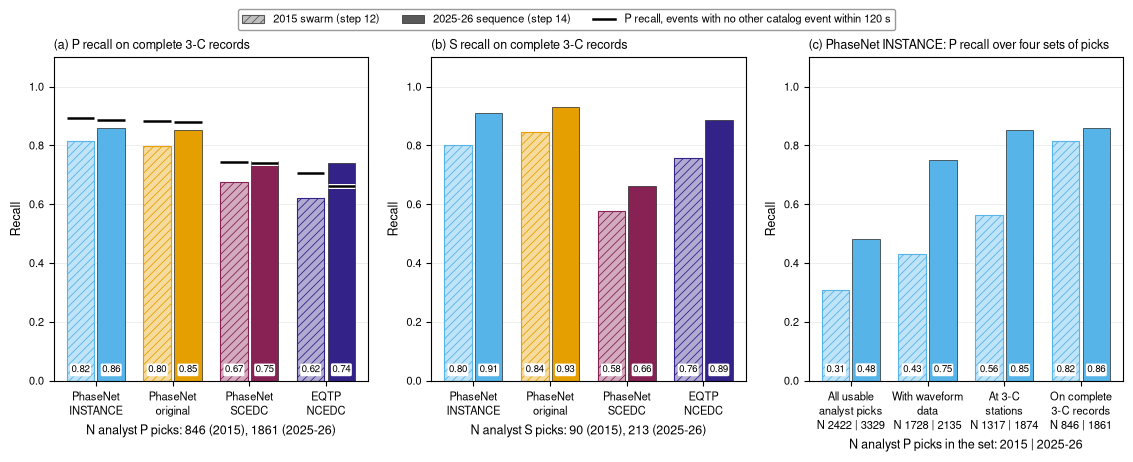

In [4]:
# Figure 1: P and S recall on complete 3-C records per model and year (a, b); recall of RECOMMENDED over the four sets (c)
ny, nm, nd = len(YEARS), len(MODELS), len(DEN)
w = BAR_GROUP_WIDTH / ny
def xpos(i, j):
    return i + (j - (ny - 1) / 2.0) * w
fig = plt.figure(figsize=(1.15 * (2 * nm + nd), FIG_HEIGHT_IN))
gs = fig.add_gridspec(1, 3, width_ratios=[nm, nm, nd], wspace=0.2)
axs = [fig.add_subplot(gs[0, i]) for i in range(3)]
for k, ph in enumerate(PH):
    ax = axs[k]
    for i, v in enumerate(MODELS):
        for j, y in enumerate(YEARS):
            x = xpos(i, j)
            r = SBM[y].loc[(v, ph), "recall_3c_complete"]
            h.year_bar(ax, x, r, 0.9 * w, COL[v], j)
            if ph == "P":
                h.level_tick(ax, x, NB[y].loc[(v, "P", ISOLATED_CLASS), "recall_3c_complete"], 0.9 * w)
            h.foot_label(ax, x, f"{r:.2f}")
    ax.set_xticks(range(nm))
    ax.set_xticklabels([TICK[v] for v in MODELS])
    ax.set_xlabel(f"N analyst {ph} picks: " + ", ".join(
        f"{int(SBM[y].loc[(MODELS[0], ph), 'n_ref_3c_complete'])} ({y})" for y in YEARS))
    ax.set_title(f"{ph} recall on complete 3-C records", loc="left")
ax = axs[2]
v = RECOMMENDED
for i, (key, lab) in enumerate(DEN):
    for j, y in enumerate(YEARS):
        x = xpos(i, j)
        r = SBM[y].loc[(v, "P"), f"recall_{key}"]
        h.year_bar(ax, x, r, 0.9 * w, COL[v], j)
        h.foot_label(ax, x, f"{r:.2f}")
ax.set_xticks(range(nd))
ax.set_xticklabels([lab + "\nN " + " | ".join(str(int(SBM[y].loc[(v, "P"), f"n_ref_{key}"])) for y in YEARS)
                    for key, lab in DEN])
ax.set_title(f"{SHORT[v]}: P recall over four sets of picks", loc="left")
ax.set_xlabel("N analyst P picks in the set: " + " | ".join(YEARS))
for k_, ax in enumerate(axs):
    ax.set_xlim(-0.55, len(ax.get_xticks()) - 0.45)
    ax.set_ylim(0, 1.1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
    ax.set_ylabel("Recall")
    h.panel_letter(ax, "abc"[k_])
h.boxed(axs)
iso_h = Line2D([], [], color="k", lw=1.8, path_effects=[pe.withStroke(linewidth=3.6, foreground="white")])
h.legend_above(fig, axs, h.year_handles() + [iso_h],
               [YEAR_LABEL[y] for y in YEARS] + ["P recall, events with no other catalog event within 120 s"], ncol=3)
FIGS["1"] = h.save_fig(fig, FIG_DIR, "09_1_recall_2015_vs_2026", dpi=FIG_DPI)
plt.show()

In [5]:
# Figure 1: what it says (numbers from the files)
def arrow(a, b, nd=2):
    return f"{a:.{nd}f} → {b:.{nd}f}"
y0, y1 = YEARS
rc = {y: SBM[y].xs("P", level="phase").loc[MODELS, "recall_3c_complete"] for y in YEARS}
rs = {y: SBM[y].xs("S", level="phase").loc[MODELS, "recall_3c_complete"] for y in YEARS}
ri = {y: pd.Series({v: NB[y].loc[(v, "P", ISOLATED_CLASS), "recall_3c_complete"] for v in MODELS}) for y in YEARS}
pn = [v for v in MODELS if v.startswith("phasenet")]
same_pn = all(f"{ri[y0][v]:.2f}" == f"{ri[y1][v]:.2f}" for v in pn)
trig = {y: SUMM[y]["n_reference"]["tiers"]["3c_incomplete"]["P"] for y in YEARS}
r_all = {y: SBM[y].loc[(RECOMMENDED, "P"), "recall_all"] for y in YEARS}
lines = [
    f"Values are {y0} → {y1}.",
    "",
    "- **P recall on complete 3-C records:** " + ", ".join(f"{SHORT[v]} {arrow(rc[y0][v], rc[y1][v])}" for v in MODELS)
    + ". The ranking of the models is " + ("the same" if list(rc[y0].sort_values().index) == list(rc[y1].sort_values().index)
                                          else "different") + " in both years.",
    "- **On events with no other catalog event within 120 s** (black lines): " + ", ".join(
        f"{SHORT[v]} {arrow(ri[y0][v], ri[y1][v])}" for v in MODELS) + ". "
    + ("The three PhaseNet models score the same to two decimals in both years: the models behave the same."
       if same_pn else "The PhaseNet models change by up to "
       f"{max(abs(ri[y1][v] - ri[y0][v]) for v in pn):.2f}."),
    "- **S recall on complete 3-C records:** " + ", ".join(f"{SHORT[v]} {arrow(rs[y0][v], rs[y1][v])}" for v in MODELS)
    + f" (over only {int(SBM[y0].loc[(MODELS[0], 'S'), 'n_ref_3c_complete'])} and "
      f"{int(SBM[y1].loc[(MODELS[0], 'S'), 'n_ref_3c_complete'])} analyst S picks).",
    f"- **Why recall over all picks rose** (panel c): complete records were {COMPLETE[y0][0]}/{COMPLETE[y0][1]} = "
    f"{COMPLETE[y0][0] / COMPLETE[y0][1]:.2f} of the main-set station-event records in {y0} and {COMPLETE[y1][0]}/{COMPLETE[y1][1]} = "
    f"{COMPLETE[y1][0] / COMPLETE[y1][1]:.2f} in {y1}, because the strong-motion records in the archive are now continuous; "
    f"analyst P picks on triggered (incomplete) 3-C records fell from {trig[y0]} to {trig[y1]}. So {SHORT[RECOMMENDED]}'s recall "
    f"over all usable analyst P picks rose ({arrow(r_all[y0], r_all[y1])}), while on complete records it moved only "
    f"{arrow(rc[y0][RECOMMENDED], rc[y1][RECOMMENDED])}.",
]
display(Markdown("\n".join(lines)))

Values are 2015 → 2025-26.

- **P recall on complete 3-C records:** PhaseNet INSTANCE 0.82 → 0.86, PhaseNet original 0.80 → 0.85, PhaseNet SCEDC 0.67 → 0.75, EQTP NCEDC 0.62 → 0.74. The ranking of the models is the same in both years.
- **On events with no other catalog event within 120 s** (black lines): PhaseNet INSTANCE 0.89 → 0.89, PhaseNet original 0.88 → 0.88, PhaseNet SCEDC 0.74 → 0.74, EQTP NCEDC 0.71 → 0.66. The three PhaseNet models score the same to two decimals in both years: the models behave the same.
- **S recall on complete 3-C records:** PhaseNet INSTANCE 0.80 → 0.91, PhaseNet original 0.84 → 0.93, PhaseNet SCEDC 0.58 → 0.66, EQTP NCEDC 0.76 → 0.89 (over only 90 and 213 analyst S picks).
- **Why recall over all picks rose** (panel c): complete records were 1789/3291 = 0.54 of the main-set station-event records in 2015 and 4625/4681 = 0.99 in 2025-26, because the strong-motion records in the archive are now continuous; analyst P picks on triggered (incomplete) 3-C records fell from 471 to 13. So PhaseNet INSTANCE's recall over all usable analyst P picks rose (0.31 → 0.48), while on complete records it moved only 0.82 → 0.86.

## Figure 2: pick-time accuracy and false picks

**What is shown.** (a): the median absolute time difference |dt| between each model's P picks and the matched analyst
P picks (dt = DL pick time − analyst pick time). (b): false P picks per station-hour, counted in the stretches of
pre-event noise that lie outside every NCSS catalog event window (the same span for all models of one year). Pale
hatched bars are 2015, solid bars 2025-26.

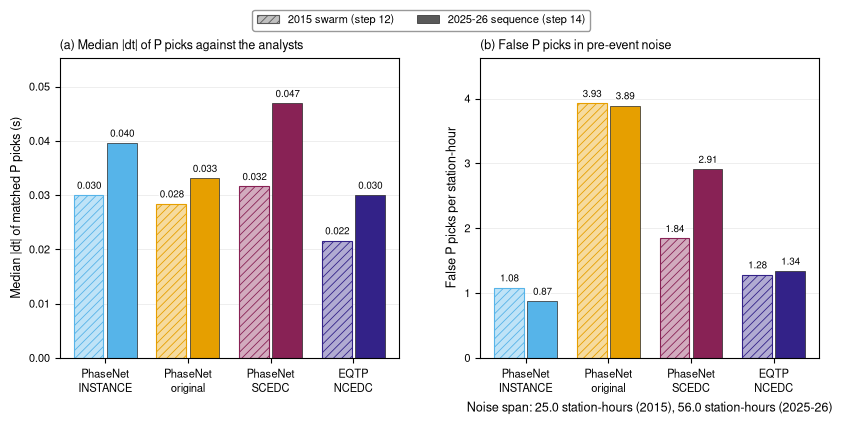

In [6]:
# Figure 2: median |dt| of the matched P picks (a) and false P picks per station-hour of pre-event noise (b)
fig = plt.figure(figsize=(1.15 * 2 * nm + 0.6, FIG_HEIGHT_IN - 0.3))
gs = fig.add_gridspec(1, 2, width_ratios=[nm, nm], wspace=0.24)
axs = [fig.add_subplot(gs[0, i]) for i in range(2)]
PANELS2 = [("median |dt|", lambda y, v: SBM[y].loc[(v, "P"), "median_abs_dt_s"], "{:.3f}", "Median |dt| of matched P picks (s)",
            "Median |dt| of P picks against the analysts"),
           ("false P", lambda y, v: OW[y].loc[(v, "P"), "false_per_station_hour_searchable"], "{:.2f}",
            "False P picks per station-hour", "False P picks in pre-event noise")]
for k, (_, get, fmt, ylab, ttl) in enumerate(PANELS2):
    ax = axs[k]
    top = 0.0
    for i, v in enumerate(MODELS):
        for j, y in enumerate(YEARS):
            x = xpos(i, j)
            val = get(y, v)
            h.year_bar(ax, x, val, 0.9 * w, COL[v], j)
            top = max(top, val)
    for i, v in enumerate(MODELS):
        for j, y in enumerate(YEARS):
            h.value_label(ax, xpos(i, j), get(y, v), fmt.format(get(y, v)), pad=0.015 * top)
    ax.set_ylim(0, 1.18 * top)
    ax.set_xticks(range(nm))
    ax.set_xticklabels([TICK[v] for v in MODELS])
    ax.set_xlim(-0.55, nm - 0.45)
    ax.set_ylabel(ylab)
    ax.set_title(ttl, loc="left")
    ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
    h.panel_letter(ax, "ab"[k])
axs[1].set_xlabel("Noise span: " + ", ".join(
    f"{OW[y].loc[(MODELS[0], 'P'), 'station_hours_searchable']:.1f} station-hours ({y})" for y in YEARS))
h.boxed(axs)
h.legend_above(fig, axs, h.year_handles(), [YEAR_LABEL[y] for y in YEARS], ncol=2)
FIGS["2"] = h.save_fig(fig, FIG_DIR, "09_2_timing_and_false_picks", dpi=FIG_DPI)
plt.show()

In [7]:
# Figure 2: what it says
mdt = {y: SBM[y].xs("P", level="phase").loc[MODELS, "median_abs_dt_s"] for y in YEARS}
p95 = {y: SBM[y].xs("P", level="phase").loc[MODELS, "p95_abs_dt_s"] for y in YEARS}
off = {y: SBM[y].xs("P", level="phase").loc[MODELS, "mean_dt_s"] for y in YEARS}
fp = {y: OW[y].xs("P", level="phase").loc[MODELS, "false_per_station_hour_searchable"] for y in YEARS}
larger = all(mdt[y1][v] > mdt[y0][v] for v in MODELS)
fewest = {y: fp[y].idxmin() for y in YEARS}
most = {y: fp[y].idxmax() for y in YEARS}
lines = [
    "- **Median |dt| of P** (s): " + ", ".join(f"{SHORT[v]} {arrow(mdt[y0][v], mdt[y1][v], 3)}" for v in MODELS)
    + (f"; slightly larger in {y1} for every model." if larger else ".")
    + " The p95 |dt| is " + ", ".join(f"{p95[y1][v]:.2f}" for v in MODELS) + f" s in {y1} (same order).",
    "- **The mean dt is a property of each model** and repeats between the years: " + ", ".join(
        f"{SHORT[v]} {1000 * off[y0][v]:+.0f} → {1000 * off[y1][v]:+.0f} ms" for v in MODELS)
    + ". A constant offset cancels in double-difference relocation when all events are picked by the same model.",
    "- **False P picks per station-hour:** " + ", ".join(f"{SHORT[v]} {arrow(fp[y0][v], fp[y1][v])}" for v in MODELS)
    + ". " + (f"{SHORT[fewest[y1]]} makes the fewest in both years" if fewest[y0] == fewest[y1]
              else f"The fewest: {SHORT[fewest[y0]]} ({y0}), {SHORT[fewest[y1]]} ({y1})")
    + (f", {SHORT[most[y1]]} the most." if most[y0] == most[y1]
       else f"; the most: {SHORT[most[y0]]} ({y0}), {SHORT[most[y1]]} ({y1}).")
    + " Many of these picks coincide at several stations and may be small uncatalogued events, so they are an upper "
      "bound of the true false-pick rate.",
]
display(Markdown("\n".join(lines)))

- **Median |dt| of P** (s): PhaseNet INSTANCE 0.030 → 0.040, PhaseNet original 0.028 → 0.033, PhaseNet SCEDC 0.032 → 0.047, EQTP NCEDC 0.022 → 0.030; slightly larger in 2025-26 for every model. The p95 |dt| is 0.21, 0.23, 0.32, 0.17 s in 2025-26 (same order).
- **The mean dt is a property of each model** and repeats between the years: PhaseNet INSTANCE -20 → -25 ms, PhaseNet original +42 → +46 ms, PhaseNet SCEDC +34 → +54 ms, EQTP NCEDC +14 → +18 ms. A constant offset cancels in double-difference relocation when all events are picked by the same model.
- **False P picks per station-hour:** PhaseNet INSTANCE 1.08 → 0.87, PhaseNet original 3.93 → 3.89, PhaseNet SCEDC 1.84 → 2.91, EQTP NCEDC 1.28 → 1.34. PhaseNet INSTANCE makes the fewest in both years, PhaseNet original the most. Many of these picks coincide at several stations and may be small uncatalogued events, so they are an upper bound of the true false-pick rate.

## Figure 3: first-motion polarity of `eqtp_ncedc`

**What is shown.** Of the DL P picks of `eqtp_ncedc` that match an analyst P pick with a first motion (up or
down), on normally oriented vertical channels: (a) the *coverage*, the share that also gets a DL polarity at
polarityMinConfidence 0.5 (plugin default) and 0.7; (b) the *agreement*, the share
of those polarities equal to the analyst's first motion. Pale hatched bars are 2015, solid bars 2025-26.

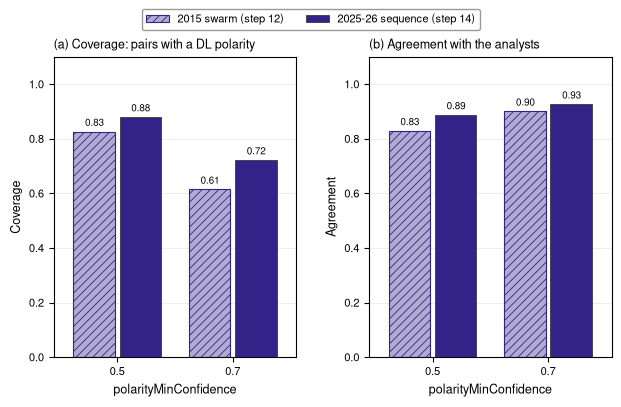

In [8]:
# Figure 3: eqtp_ncedc polarity coverage (a) and agreement (b) at the two thresholds, normally oriented channels
nt = len(POL_THRESHOLDS)
fig = plt.figure(figsize=(1.15 * 2 * nt + 2.6, FIG_HEIGHT_IN - 0.3))
gs = fig.add_gridspec(1, 2, width_ratios=[nt, nt], wspace=0.3)
axs = [fig.add_subplot(gs[0, i]) for i in range(2)]
for k, (key, ttl) in enumerate((("coverage", "Coverage: pairs with a DL polarity"),
                                ("agreement", "Agreement with the analysts"))):
    ax = axs[k]
    for i, thr in enumerate(POL_THRESHOLDS):
        for j, y in enumerate(YEARS):
            x = xpos(i, j)
            val = POL[y][f"thr_{thr:g}"][POL_GROUP][key]
            h.year_bar(ax, x, val, 0.9 * w, COL[POLARITY_MODEL], j)
            h.value_label(ax, x, val, f"{val:.2f}")
    ax.set_xticks(range(nt))
    ax.set_xticklabels([f"{thr:g}" for thr in POL_THRESHOLDS])
    ax.set_xlabel("polarityMinConfidence")
    ax.set_xlim(-0.55, nt - 0.45)
    ax.set_ylim(0, 1.1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_ylabel(key.capitalize())
    ax.set_title(ttl, loc="left")
    ax.grid(axis="y", color="0.92", lw=0.6, zorder=0)
    h.panel_letter(ax, "ab"[k])
h.boxed(axs)
h.legend_above(fig, axs, h.year_handles(COL[POLARITY_MODEL]), [YEAR_LABEL[y] for y in YEARS], ncol=2)
FIGS["3"] = h.save_fig(fig, FIG_DIR, "09_3_eqtp_polarity", dpi=FIG_DPI)
plt.show()

In [9]:
# Figure 3: what it says, and the inverted-channel caveat
t0, t1 = (f"thr_{t:g}" for t in POL_THRESHOLDS)
g = {(y, t): POL[y][t][POL_GROUP] for y in YEARS for t in (t0, t1)}
gi = {(y, t): POL[y][t][POL_GROUP_INVERTED] for y in YEARS for t in (t0, t1)}
lines = [
    f"- **Normally oriented channels, {y1}:** coverage / agreement {g[(y1, t0)]['coverage']:.2f} / {g[(y1, t0)]['agreement']:.2f} "
    f"at {POL_THRESHOLDS[0]:g} and {g[(y1, t1)]['coverage']:.2f} / {g[(y1, t1)]['agreement']:.2f} at {POL_THRESHOLDS[1]:g} "
    f"({y0}: {g[(y0, t0)]['coverage']:.2f} / {g[(y0, t0)]['agreement']:.2f} and {g[(y0, t1)]['coverage']:.2f} / "
    f"{g[(y0, t1)]['agreement']:.2f}); over {g[(y1, t0)]['n_matched_with_analyst_fm']} and "
    f"{g[(y0, t0)]['n_matched_with_analyst_fm']} matched P picks with an analyst first motion.",
    f"- **Threshold {POL_THRESHOLDS[1]:g} trades coverage for reliability:** in {y1} it gives up "
    f"{g[(y1, t0)]['coverage'] - g[(y1, t1)]['coverage']:.2f} of the coverage for "
    f"{g[(y1, t1)]['agreement'] - g[(y1, t0)]['agreement']:+.2f} agreement; it is the better choice for focal mechanisms.",
    f"- **Caveat, inverted channels** (negative gain or dip +90°, left out of the figure): agreement is only "
    f"{gi[(y1, t0)]['agreement']:.2f} (n {gi[(y1, t0)]['n_matched_with_analyst_fm']}) in {y1} and {gi[(y0, t0)]['agreement']:.2f} "
    f"(n {gi[(y0, t0)]['n_matched_with_analyst_fm']}) in {y0}, but {gi[(y1, t0)]['agreement_raw_counts']:.2f} when the plugin's "
    "sign swap is undone. The analysts' first motions on those channels follow the raw counts, not the ground motion: in "
    f"an independent test without any DL model they agree with similar rays on normal channels in only "
    f"{PRC[y1]['inverted_frac_same']:.2f} of {PRC[y1]['inverted_tests']} tests, against {PRC[y1]['control_frac_same']:.2f} of "
    f"{PRC[y1]['control_tests']} for normal channels ({y0}: {PRC[y0]['inverted_frac_same']:.2f} of {PRC[y0]['inverted_tests']} "
    f"against {PRC[y0]['control_frac_same']:.2f}). The plugin's polarity is consistent with the station metadata; the NCSS "
    "first motions of those channels need correcting before they are used.",
]
display(Markdown("\n".join(lines)))

- **Normally oriented channels, 2025-26:** coverage / agreement 0.88 / 0.89 at 0.5 and 0.72 / 0.93 at 0.7 (2015: 0.83 / 0.83 and 0.61 / 0.90); over 1039 and 524 matched P picks with an analyst first motion.
- **Threshold 0.7 trades coverage for reliability:** in 2025-26 it gives up 0.16 of the coverage for +0.04 agreement; it is the better choice for focal mechanisms.
- **Caveat, inverted channels** (negative gain or dip +90°, left out of the figure): agreement is only 0.04 (n 26) in 2025-26 and 0.21 (n 51) in 2015, but 0.96 when the plugin's sign swap is undone. The analysts' first motions on those channels follow the raw counts, not the ground motion: in an independent test without any DL model they agree with similar rays on normal channels in only 0.24 of 147 tests, against 0.82 of 595 for normal channels (2015: 0.32 of 148 against 0.70). The plugin's polarity is consistent with the station metadata; the NCSS first motions of those channels need correcting before they are used.

## Summary

The table collects the key numbers per model and year (complete = analyst picks on complete 3-C records; isolated =
the same on events with no other catalog event within 120 s; F1 = 2 × recall × precision / (recall + precision), the
pooled P+S F1 being the ranking rule fixed in step 12).

In [10]:
# summary table: model x key numbers, both years
COLS = [("P recall, complete", "{:.2f}"), ("P recall, isolated", "{:.2f}"), ("S recall, complete", "{:.2f}"),
        ("P median |dt| (s)", "{:.3f}"), ("False P per station-hour", "{:.2f}"), ("P-only F1", "{:.3f}"),
        ("Pooled P+S F1", "{:.3f}"), ("CPU-s per station-hour", "{:.3f}")]
rows = []
for v in MODELS:
    for y in YEARS:
        s = SBM[y]
        rows.append({"model": SHORT[v], "years": y,
                     "P recall, complete": s.loc[(v, "P"), "recall_3c_complete"],
                     "P recall, isolated": NB[y].loc[(v, "P", ISOLATED_CLASS), "recall_3c_complete"],
                     "S recall, complete": s.loc[(v, "S"), "recall_3c_complete"],
                     "P median |dt| (s)": s.loc[(v, "P"), "median_abs_dt_s"],
                     "False P per station-hour": OW[y].loc[(v, "P"), "false_per_station_hour_searchable"],
                     "P-only F1": s.loc[(v, "P"), "f1"],
                     "Pooled P+S F1": s.loc[(v, "P+S"), "f1"],
                     "CPU-s per station-hour": COST[y].loc[v, "cpu_s_per_station_hour"]})
SUMMARY = pd.DataFrame(rows).set_index(["model", "years"])
display(SUMMARY.apply(lambda c: c.map(dict(COLS)[c.name].format)))

P recall, complete P recall, isolated S recall, complete P median |dt| (s) False P per station-hour P-only F1 Pooled P+S F1 CPU-s per station-hour
model             years                                                                                                                                                     
PhaseNet INSTANCE 2015                  0.82               0.89               0.80             0.030                     1.08     0.635         0.505                  0.229
                  2025-26               0.86               0.89               0.91             0.040                     0.87     0.783         0.615                  0.215
PhaseNet original 2015                  0.80               0.88               0.84             0.028                     3.93     0.592         0.438                  0.250
                  2025-26               0.85               0.88               0.93             0.033                     3.89     0.748         0.542                  0.225
PhaseNet SCEDC    2015                  0.67               0.74               0.58             0.032                     1.84     0.568         0.488                  0.216
                  2025-26               0.75               0.74               0.66             0.047                     2.91     0.745         0.640                  0.199
EQTP NCEDC        2015                  0.62               0.71               0.76             0.022                     1.28     0.576         0.460                  3.920
                  2025-26               0.74               0.66               0.89             0.030                     1.34     0.715         0.542                  5.013

In [11]:
# take-home messages and caveats (numbers from the files)
SY = {y: SUMMARY.xs(y, level="years").set_axis(MODELS) for y in YEARS}
S1 = SY[y1]
def rank_of(y, col, v, high_is_good=True):
    return SY[y][col].sort_values(ascending=not high_is_good).index.tolist().index(v)
def rank_word(col, v, high_is_good=True):
    k = rank_of(y1, col, v, high_is_good)
    return (["the highest", "the second highest", "the third highest", "the lowest"] if high_is_good
            else ["the lowest", "the second lowest", "the third lowest", "the highest"])[k]
same_rank = all(rank_of(y0, c_, RECOMMENDED, hi) == rank_of(y1, c_, RECOMMENDED, hi) for c_, hi in
                (("P recall, complete", True), ("False P per station-hour", False), ("P-only F1", True)))
best = SUMM[y1]["best_model"]
rk = pd.DataFrame(best["ranking"]).set_index("variant")
sP = {y: SBM[y].xs("S", level="phase").loc[MODELS] for y in YEARS}
n_ref = {y: (SUMM[y]["n_reference"]["P"], SUMM[y]["n_reference"]["S"]) for y in YEARS}
pn_s = [v for v in pn if v != best["best_model"]]
ov = {y: BYEV[y][(BYEV[y].event_id == OVERLAP_EVENT[y]) & (BYEV[y].phase == "P")].set_index("variant")
      .loc[MODELS, "recall_3c_complete"] for y in YEARS}
nb_ = NEIGH[y1].loc[OVERLAP_EVENT[y1]]
xf = XC[f"overlap_file_{OVERLAP_EVENT[y1]}_matched_P_by_event"]
cost = {y: COST[y].loc[MODELS, "cpu_s_per_station_hour"] for y in YEARS}
ratio = cost[y1][POLARITY_MODEL] / cost[y1][pn]
R = RECOMMENDED
take = [
    f"- **Use `{R}`.** In {y1} its P recall on complete records ({S1.loc[R, 'P recall, complete']:.2f}) is "
    f"{rank_word('P recall, complete', R)} of the four models, its false P rate ({S1.loc[R, 'False P per station-hour']:.2f} per "
    f"station-hour) {rank_word('False P per station-hour', R, False)} and its P-only F1 ({S1.loc[R, 'P-only F1']:.3f}) "
    f"{rank_word('P-only F1', R)}" + (f", as in {y0}." if same_rank else f" (ranks differ in {y0}).")
    + f" Its S recall on complete records is {S1.loc[R, 'S recall, complete']:.2f}.",
    f"- **Do not read the pooled ranking rule literally.** The rule fixed in step 12 (highest pooled P+S F1) now names "
    f"`{best['best_model']}` ({rk.loc[best['best_model'], 'f1']:.3f}, then `{rk.index[1]}` {rk.iloc[1]['f1']:.3f}). It wins only "
    f"on S precision ({sP[y1].loc[best['best_model'], 'precision']:.2f} against "
    f"{sP[y1].loc[pn_s, 'precision'].min():.2f}–{sP[y1].loc[pn_s, 'precision'].max():.2f}), because it makes the fewest S picks "
    f"({int(sP[y1].loc[best['best_model'], 'n_dl_in_window'])} against "
    f"{int(sP[y1].loc[pn_s, 'n_dl_in_window'].min())}–{int(sP[y1].loc[pn_s, 'n_dl_in_window'].max())}) while the analysts picked S "
    f"at only {n_ref[y1][1]} station-events (P: {n_ref[y1][0]}). Its S recall ({sP[y1].loc[best['best_model'], 'recall_3c_complete']:.2f}) "
    "is the lowest of the PhaseNet models.",
    f"- **The models behave the same; the data changed.** On events without neighbors the PhaseNet P recall is "
    + ", ".join(f"{arrow(ri[y0][v], ri[y1][v])}" for v in pn)
    + f" ({y0} → {y1}); recall over all analyst picks rose because the share of complete records went from "
      f"{COMPLETE[y0][0] / COMPLETE[y0][1]:.2f} to {COMPLETE[y1][0] / COMPLETE[y1][1]:.2f}.",
    f"- **Close event pairs lose one event.** Overlap event {OVERLAP_EVENT[y1]} lies {nb_.nearest_dt_s:.1f} s before an "
    f"M {nb_.nearest_mag:.2f} ({nb_.nearest_other_event}). The PhaseNet models find {ov[y1][pn].min():.2f}–{ov[y1][pn].max():.2f} of "
    f"its P onsets, because their windows keep the larger event; `{POLARITY_MODEL}` finds {ov[y1][POLARITY_MODEL]:.2f} but then "
    f"matches only {xf[POLARITY_MODEL][nb_.nearest_other_event]} P picks of the M {nb_.nearest_mag:.2f}, against "
    f"{xf[R][nb_.nearest_other_event]} for `{R}`. In {y0} the overlap event {OVERLAP_EVENT[y0]} had a P recall of "
    f"{ov[y0].min():.2f}–{ov[y0].max():.2f} (highest for `{ov[y0].idxmax()}`).",
    f"- **`{POLARITY_MODEL}` costs {ratio.min():.0f}–{ratio.max():.0f} times as much CPU** as the PhaseNet models "
    f"({cost[y1][POLARITY_MODEL]:.2f} against {cost[y1][pn].min():.2f}–{cost[y1][pn].max():.2f} CPU-s per station-hour; {y0}: "
    f"{(cost[y0][POLARITY_MODEL] / cost[y0][pn]).min():.0f}–{(cost[y0][POLARITY_MODEL] / cost[y0][pn]).max():.0f} times) and finds "
    f"fewer P onsets, but it is the only model that gives first-motion polarity ({g[(y1, t1)]['agreement']:.2f} agreement at "
    f"threshold {POL_THRESHOLDS[1]:g} on normally oriented channels).",
]
nbin = {y: EVT[y].reason.str.extract(r"magnitude bin ([^,]+),")[0] for y in YEARS}
def sel_txt(y):
    c = nbin[y].value_counts()
    per = f"{c.min()}" if c.min() == c.max() else f"{c.min()}–{c.max()}"
    return f"{per} per magnitude bin in {len(c)} bins plus {int(nbin[y].isna().sum())} chosen for other reasons"
hn_st = COV[y1].loc[COV[y1].role == "hn"].groupby(["network", "station"]).ngroups
cav = [
    f"- **The reference is incomplete.** The analysts picked S at {n_ref[y1][1]} station-events against {n_ref[y1][0]} for P "
    f"({y0}: {n_ref[y0][1]} and {n_ref[y0][0]}), so precision is a lower bound and S precision says little about a picker.",
    f"- **Small samples.** {len(EVT[y0])} and {len(EVT[y1])} test events: "
    + (f"in each year {sel_txt(y1)}" if sel_txt(y0) == sel_txt(y1) else " and ".join(f"{sel_txt(y)} ({y})" for y in YEARS))
    + ", with one overlap event per year.",
    "- **The two years differ in more than the sequence.** The networks changed (more broadband stations, most of the "
    "triggered NetQuakes strong-motion sites gone, the remaining strong-motion records continuous), and the analysts' picks "
    "reach farther. Recall over all picks and over picks with data is therefore not comparable between the years as a "
    "measure of the models; the complete-record and isolated-event numbers are.",
    "- **Inverted channels** are left out of Figure 3 for the reason given in the text under it.",
    f"- **Not shown here:** the accelerometer binding set ({len(XC['hn_failed_three_component_assembly'])} of its {hn_st} "
    "accelerometers gave no picks because of split sensor-location epochs in the station metadata), the SeisBench cross-check "
    "and the per-sensor, per-distance and per-magnitude breakdowns; see `docs/results/14_sanramon2026_dlpicker.md`.",
]
display(Markdown("**Take-home messages**\n\n" + "\n".join(take) + "\n\n**Caveats**\n\n" + "\n".join(cav)))
print("figures written:")
for k_, (png, pdf) in FIGS.items():
    print(f"  Figure {k_}: {png}  |  {pdf}")

**Take-home messages**

- **Use `phasenet_instance`.** In 2025-26 its P recall on complete records (0.86) is the highest of the four models, its false P rate (0.87 per station-hour) the lowest and its P-only F1 (0.783) the highest, as in 2015. Its S recall on complete records is 0.91.
- **Do not read the pooled ranking rule literally.** The rule fixed in step 12 (highest pooled P+S F1) now names `phasenet_scedc` (0.640, then `phasenet_instance` 0.615). It wins only on S precision (0.17 against 0.10–0.13), because it makes the fewest S picks (891 against 1709–2398) while the analysts picked S at only 229 station-events (P: 3329). Its S recall (0.66) is the lowest of the PhaseNet models.
- **The models behave the same; the data changed.** On events without neighbors the PhaseNet P recall is 0.89 → 0.89, 0.88 → 0.88, 0.74 → 0.74 (2015 → 2025-26); recall over all analyst picks rose because the share of complete records went from 0.54 to 0.99.
- **Close event pairs lose one event.** Overlap event 75283011 lies 5.5 s before an M 3.77 (75283016). The PhaseNet models find 0.11–0.39 of its P onsets, because their windows keep the larger event; `eqtp_ncedc` finds 0.80 but then matches only 33 P picks of the M 3.77, against 145 for `phasenet_instance`. In 2015 the overlap event 72540760 had a P recall of 0.04–0.28 (highest for `eqtp_ncedc`).
- **`eqtp_ncedc` costs 22–25 times as much CPU** as the PhaseNet models (5.01 against 0.20–0.22 CPU-s per station-hour; 2015: 16–18 times) and finds fewer P onsets, but it is the only model that gives first-motion polarity (0.93 agreement at threshold 0.7 on normally oriented channels).

**Caveats**

- **The reference is incomplete.** The analysts picked S at 229 station-events against 3329 for P (2015: 163 and 2422), so precision is a lower bound and S precision says little about a picker.
- **Small samples.** 26 and 26 test events: in each year 4 per magnitude bin in 6 bins plus 2 chosen for other reasons, with one overlap event per year.
- **The two years differ in more than the sequence.** The networks changed (more broadband stations, most of the triggered NetQuakes strong-motion sites gone, the remaining strong-motion records continuous), and the analysts' picks reach farther. Recall over all picks and over picks with data is therefore not comparable between the years as a measure of the models; the complete-record and isolated-event numbers are.
- **Inverted channels** are left out of Figure 3 for the reason given in the text under it.
- **Not shown here:** the accelerometer binding set (3 of its 28 accelerometers gave no picks because of split sensor-location epochs in the station metadata), the SeisBench cross-check and the per-sensor, per-distance and per-magnitude breakdowns; see `docs/results/14_sanramon2026_dlpicker.md`.

figures written:
  Figure 1: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/09_1_recall_2015_vs_2026.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/09_1_recall_2015_vs_2026.pdf
  Figure 2: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/09_2_timing_and_false_picks.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/09_2_timing_and_false_picks.pdf
  Figure 3: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/09_3_eqtp_polarity.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/09_3_eqtp_polarity.pdf


### How to reproduce

```bash
# this notebook (loads the results of steps 12 and 14; no picking)
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks
source /home/msseo/miniforge3/etc/profile.d/conda.sh && conda activate pyrtdd
python build_09_sanramon2026_dlpicker.py        # writes 09_sanramon2026_dlpicker.ipynb (compiles every code cell)
rm -f figures/09_*.png figures/09_*.pdf
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=pyrtdd \
    --ExecutePreprocessor.timeout=600 09_sanramon2026_dlpicker.ipynb

# the step 14 results themselves (not needed for this notebook): dry run first
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon2026/dlpicker
bash scripts/14_dlpicker.sh                        # dry run: prints what would be done
bash scripts/14_dlpicker.sh --apply                # prep, pick, compare, tables
bash scripts/14_dlpicker.sh --apply --stage seisbench
python -I scripts/14_extra_checks.py --run-dir $PWD > analysis/extra_checks_console.txt
python -I scripts/14_side_by_side.py --run-2015 ../../sanramon/dlpicker --run-2026 $PWD \
    --out analysis/side_by_side_2015_vs_2026.csv > analysis/side_by_side_2015_vs_2026.md
```

- Inputs (read only): `runs/sanramon2026/dlpicker/` and `runs/sanramon/dlpicker/` (`analysis/summary_by_model.csv`,
  `by_neighbour.csv`, `outside_window.csv`, `cost.csv`, `summary.json`, `polarity_reference_check.json`,
  `event_neighbours.csv`, `by_event.csv`, `config/coverage_bound.csv`), step 14's `extra_checks.json` and
  `side_by_side_2015_vs_2026.csv`, and the test-event tables `data/sanramon_{2015,2026}/inputs/dl_subset_events.csv`.
- Outputs: `notebooks/figures/09_*.png` (200 dpi) and `.pdf`.
- Helper code: `notebooks/lib/nb09_helpers.py` (layout helpers copied verbatim from `nb07_helpers.py`); fonts:
  `notebooks/lib/nbfont.py`. Full write-up: `docs/results/14_sanramon2026_dlpicker.md`.

In [12]:
# run time of this execution
print(f"run time {(_time.time() - T_START):.1f} s")

run time 3.4 s
